# Prototype 3 — Synthetic Student Tuning

_From "Wicked Problem Prototypes: Personalization Without the Data Districts Can't Defend" (Linda Bernard, Nov 2026)._

**ACE is developed and calibrated on simulated middle schoolers, so real student data is needed only for validation at low volume, and never for model development.**

This notebook walks through the harness. It answers the obvious objection to the two-stream model: *if QuestSim never gets student data, how does the product get better?*

> The pre-rendered figures below come from `run.py`. Re-run the code cells to regenerate them yourself (deterministic, ~10s).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
from synthetic_tuning import sample_population, SKILL_NAMES, FT_TARGET, SCAF_TARGET
from synthetic_tuning import validation as V
from synthetic_tuning import plotting
import matplotlib.pyplot as plt
print('skills:', SKILL_NAMES)

skills: ['square_numbers', 'square_roots', 'identify_hyp', 'theorem_setup', 'solve_hyp', 'solve_leg', 'word_problems']


## 1. The synthetic population

Each learner is an agent with **five parameters**, each grounded in published learning-science literature rather than invented:

| parameter | meaning | grounding |
|---|---|---|
| `prior` | initial P(skill known) | BKT — Corbett & Anderson (1995) |
| `learn_mult` | acquisition rate | power law of practice — Newell & Rosenbloom (1981) |
| `slip_mult` | error tendency when known | BKT slip |
| `hint` | hint-seeking propensity | help-seeking — Aleven et al. (2006) |
| `decay` | forgetting rate | Ebbinghaus / Pavlik & Anderson (2005) |

`shift=0` is QuestSim's optimistic synthetic prior. A positive shift makes a population harder — used to build a stand-in **real** cohort (no real child is ever involved).

In [2]:
syn = sample_population(200, seed=1, shift=0.0)      # optimistic prior
real = V.build_real_cohort()                         # harder + a high-forgetting tail
for p in ('prior','learn_mult','slip_mult','hint','decay'):
    print(f'{p:12s} synthetic mean={syn[p].mean():.2f}   real mean={real[p].mean():.2f}')

prior        synthetic mean=0.19   real mean=0.15
learn_mult   synthetic mean=0.97   real mean=0.46
slip_mult    synthetic mean=1.01   real mean=1.65
hint         synthetic mean=0.33   real mean=0.40
decay        synthetic mean=0.20   real mean=0.31


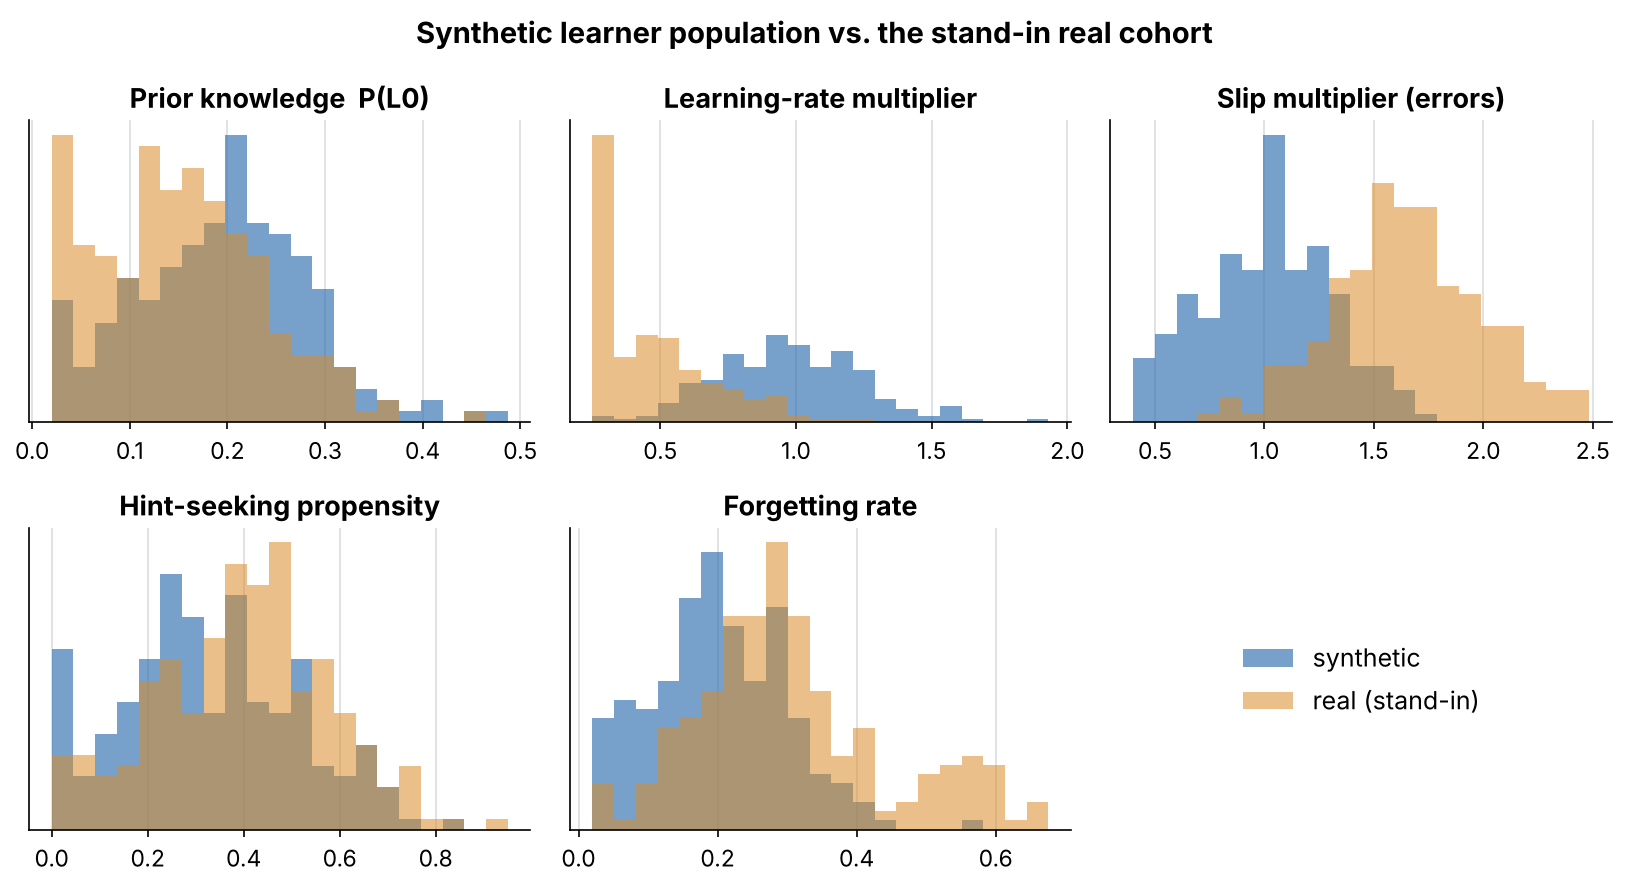

In [3]:
fig_path = plotting.plot_population(syn, real, '../figures/01_population.png')
from IPython.display import Image; Image(fig_path)

![population](../figures/01_population.png)

## 2. Calibration curves for ACE's triggers

ACE runs each student through the skill sequence, tracking per-skill mastery with Bayesian Knowledge Tracing, and fires two interventions:

- **fast-track** — advance a student who reaches mastery quickly and isn't leaning on hints;
- **scaffold** — drop in support for a student whose rolling struggle signal stays high.

Each is governed by one threshold. The calibration curve sweeps the threshold and reports the cohort firing rate, averaged over resamples, so we can choose a threshold that hits a pedagogical design target (fast-track ~15% of encounters, scaffold ~35%).

In [4]:
from synthetic_tuning import calibrate, pick_threshold, FT_GRID, SCAF_GRID
ft_curve = calibrate(syn, 'ft_thr', FT_GRID)
sc_curve = calibrate(syn, 'scaf_thr', SCAF_GRID)
ft_thr = pick_threshold(ft_curve, FT_TARGET)
sc_thr = pick_threshold(sc_curve, SCAF_TARGET)
print('chosen fast-track threshold:', ft_thr)
print('chosen scaffold  threshold:', sc_thr)

chosen fast-track threshold: 0.92
chosen scaffold  threshold: 0.75


In [5]:
plotting.plot_calibration(ft_curve, FT_TARGET, ft_thr,
    'Fast-track calibration curve (synthetic cohort)',
    '../figures/02_calibration_fasttrack.png', 'fast-track mastery threshold')
plotting.plot_calibration(sc_curve, SCAF_TARGET, sc_thr,
    'Scaffold calibration curve (synthetic cohort)',
    '../figures/03_calibration_scaffold.png', 'scaffold struggle threshold')
print('curves written')

curves written


![fast-track](../figures/02_calibration_fasttrack.png)

![scaffold](../figures/03_calibration_scaffold.png)

## 3. The test

The write-up: *compare ACE tuned on synthetic learners against ACE tuned on whatever real pilot data exists, and check whether the synthetic-tuned version performs within range on the real cohort, measured only through aggregate outcomes.*

The **within-range criterion is set before running** (per the instruction): mean mastery ±0.03, bottom-quartile ±0.05, retention ±0.03, opportunities/skill ±1.0.

In [6]:
print('pre-registered criterion:', V.WITHIN_RANGE)
wr = V.within_range_test(syn, real)
print('synthetic-tuned:', wr['syn_tuned'])
print('real-tuned     :', wr['real_tuned'])
for k in V.OUTCOME_KEYS:
    print(f"  {k:26s} delta={wr['deltas'][k]:.3f}  {'PASS' if wr['passed'][k] else 'FAIL'}")
print('OVERALL:', 'PASS' if wr['overall_pass'] else 'FAIL')

pre-registered criterion: {'mean_mastery': 0.03, 'bottom_quartile_mastery': 0.05, 'retention': 0.03, 'opportunities_per_skill': 1.0}


synthetic-tuned: {'ft_thr': 0.92, 'scaf_thr': 0.75}
real-tuned     : {'ft_thr': 0.7, 'scaf_thr': 0.8}
  mean_mastery               delta=0.003  PASS
  bottom_quartile_mastery    delta=0.014  PASS
  retention                  delta=0.002  PASS
  opportunities_per_skill    delta=0.149  PASS
OVERALL: PASS


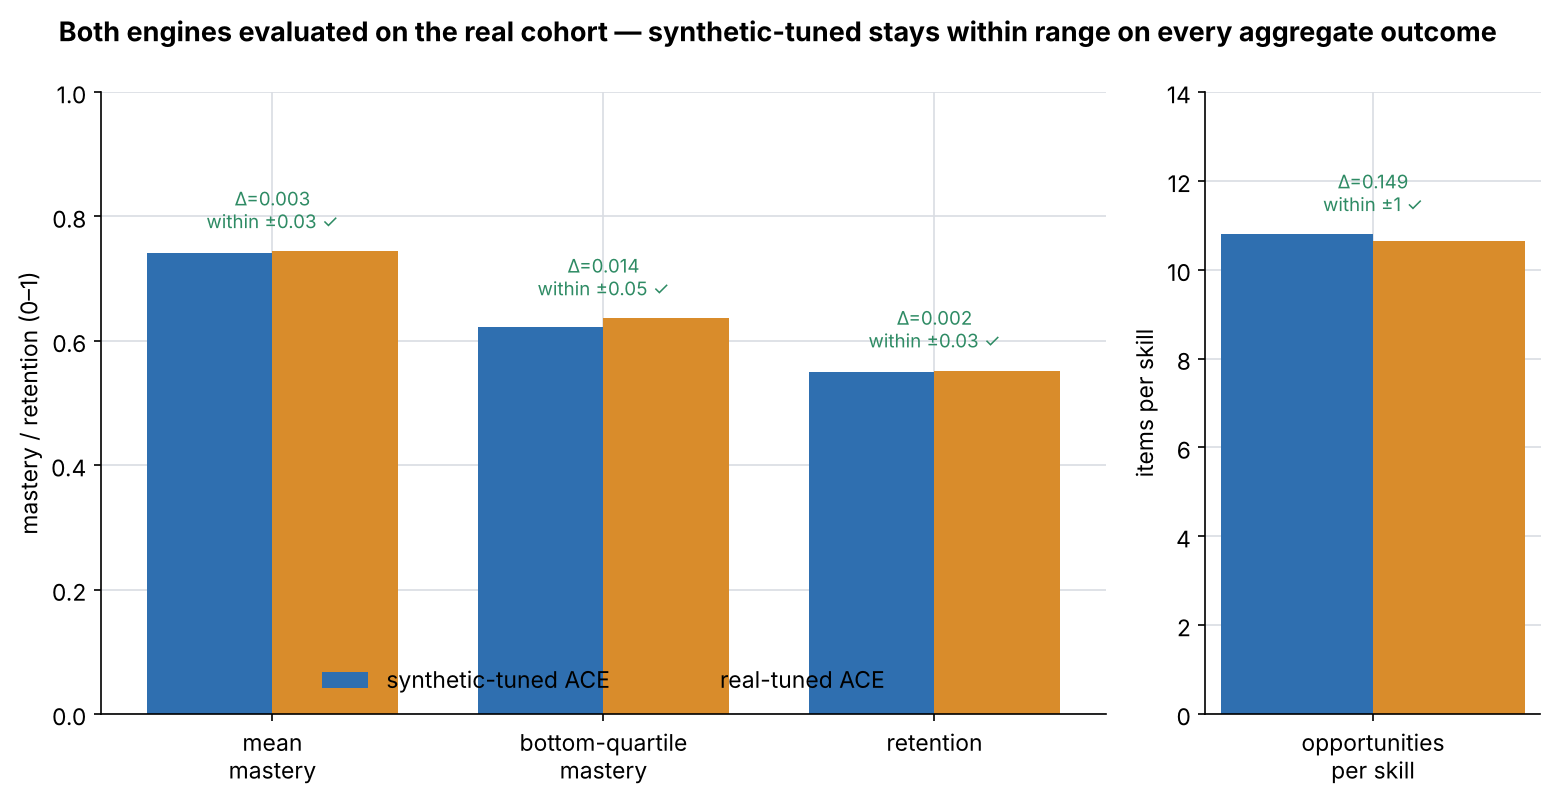

In [7]:
plotting.plot_within_range(wr, V.WITHIN_RANGE, '../figures/04_within_range.png')
Image('../figures/04_within_range.png')

![within range](../figures/04_within_range.png)

The engine built with **zero** student data lands within range of the engine that would have required real pilot records.

## 4. Transfer — an improvement found on synthetic data helps real students

Find a better scaffold threshold on synthetic data (lift the bottom-quartile strugglers, within a 40% intervention budget), then apply the **same** threshold to the real cohort. No individual record leaves the district to find it.

scaffold 0.75 -> 0.7
synthetic bottom-quartile 0.877 -> 0.890
real      bottom-quartile 0.630 -> 0.641
transfers: True


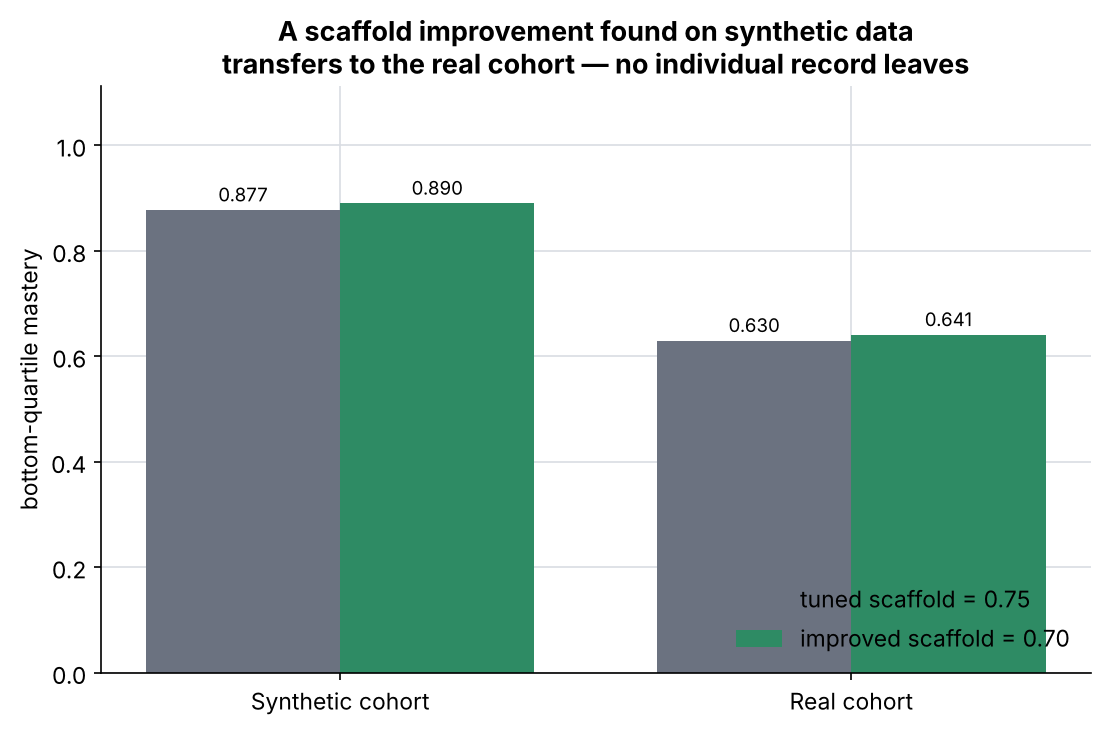

In [8]:
tr = V.transfer_test(syn, real, wr['syn_tuned']['scaf_thr'])
print(f"scaffold {tr['tuned_scaf']} -> {tr['improved_scaf']}")
print(f"synthetic bottom-quartile {tr['syn_before']:.3f} -> {tr['syn_after']:.3f}")
print(f"real      bottom-quartile {tr['real_before']:.3f} -> {tr['real_after']:.3f}")
print('transfers:', tr['transfers'])
plotting.plot_transfer(tr, '../figures/05_transfer.png')
Image('../figures/05_transfer.png')

![transfer](../figures/05_transfer.png)

## 5. Aggregate-only feedback

The only thing the engineering stream consumes from the real world is **one number**: the real cohort's fast-track firing rate. Feeding it back re-grounds the synthetic population's difficulty — recovering the real shift without reading any record.

real fast-track rate = 0.046  (the ONE number shared)
recovered shift = 0.55  (true = 0.60)
aggregates used = 1


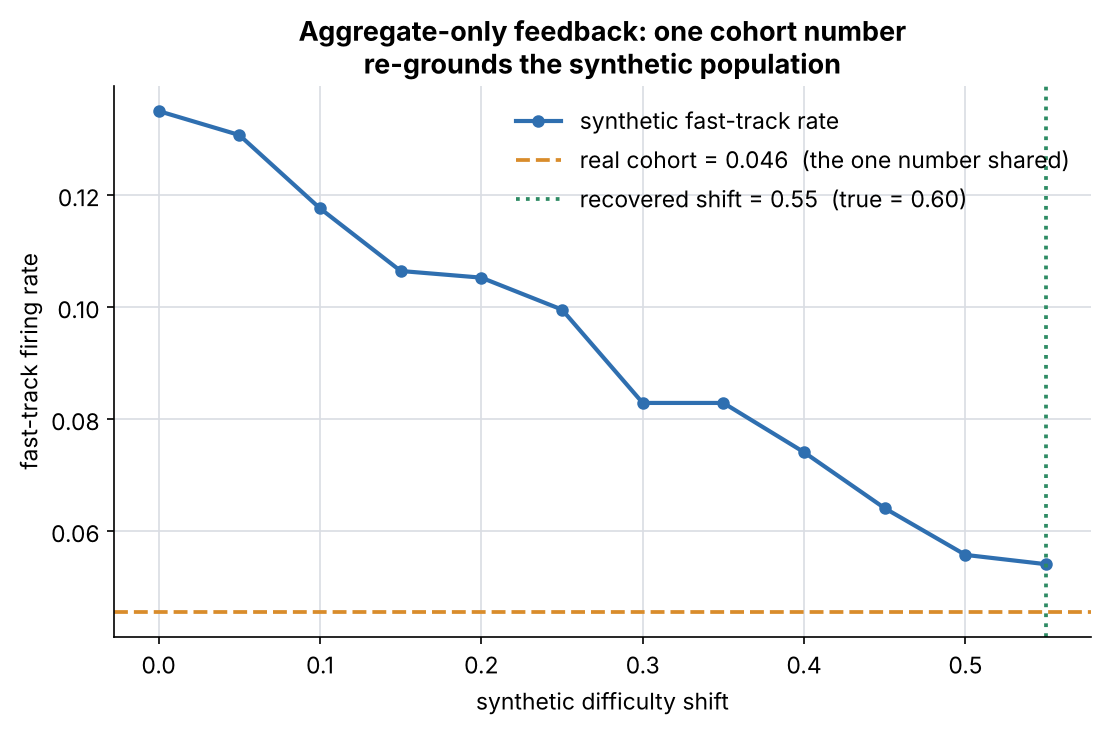

In [9]:
af = V.aggregate_feedback(real, wr['syn_tuned']['ft_thr'])
print(f"real fast-track rate = {af['real_ft_rate']:.3f}  (the ONE number shared)")
print(f"recovered shift = {af['recovered_shift']:.2f}  (true = {af['true_shift']:.2f})")
print(f"aggregates used = {af['n_aggregates_used']}")
plotting.plot_feedback(af, '../figures/06_aggregate_feedback.png')
Image('../figures/06_aggregate_feedback.png')

![feedback](../figures/06_aggregate_feedback.png)

## 6. The caveat (state this in class)

A synthetic population tuned to match real aggregates can still be wrong about individuals in ways that only show up in real classrooms. The stand-in real cohort carries a high-forgetting tail the synthetic priors cannot express. After matching the aggregate, the **retention** gap is the one that remains — and it is invisible to the aggregate the feedback loop used.

That is exactly why the two streams validate each other rather than one replacing the other.

mean-mastery gap (matched aggregate) = 0.020
retention gap (the blind spot)       = 0.041


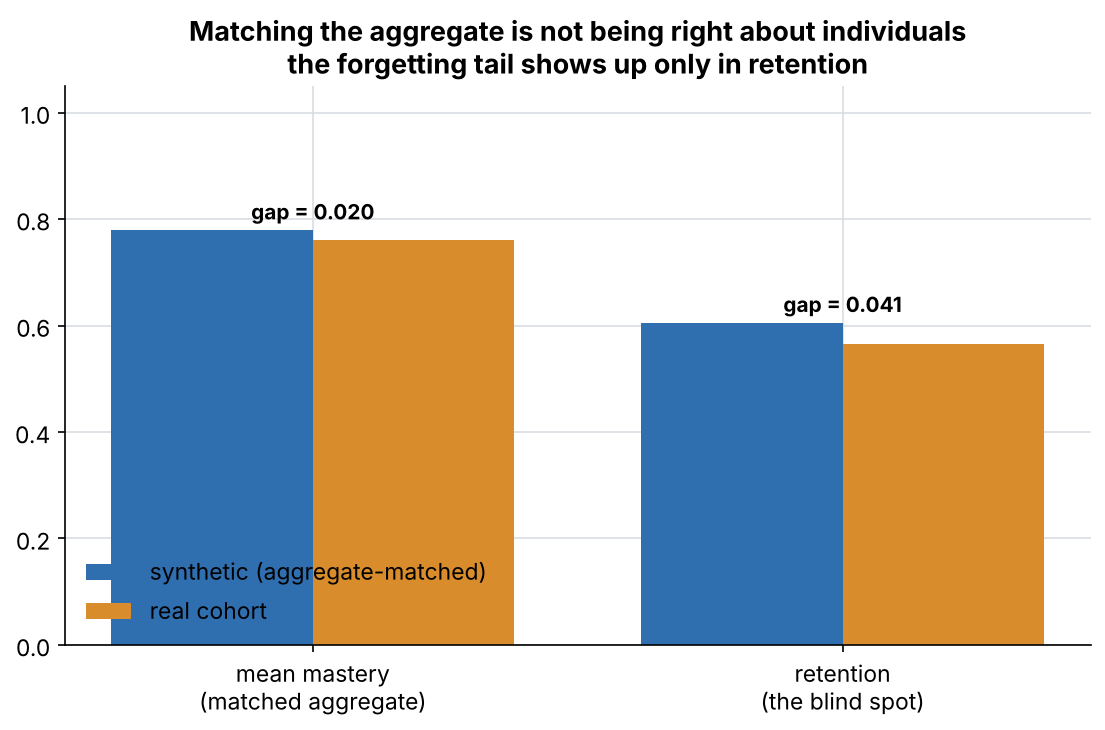

In [10]:
cv = V.caveat_demo(real, af['recovered_shift'])
print(f"mean-mastery gap (matched aggregate) = {cv['mastery_gap']:.3f}")
print(f"retention gap (the blind spot)       = {cv['retention_gap']:.3f}")
plotting.plot_caveat(cv, '../figures/07_caveat_retention.png')
Image('../figures/07_caveat_retention.png')

![caveat](../figures/07_caveat_retention.png)

## What this answers

> We built the brain on simulated students; your kids only ever confirm it works.

The two-stream architecture holds: QuestSim develops and tunes ACE in simulation, and real students only ever contribute low-volume, aggregate confirmation — never individual records for model development.